# Lab 3 Pre-Lab: Neural Networks & Computer Vision Basics

You are NOT allowed to import any other libraries in this notebook otherwise points will be deducted. If you need to, please confirm with the TA.
`''' TODO '''` Indicates where your solution code should go. Please ensure code is readable easily.

For a further resource to the material covered in class, please check the following link. It is an introduction to constructing a simple neural network including ReLU and sigmoid activation functions, please read this tutorial before completing the prelab: [Deep Neural Network Step by Step](https://massivefile.com/Building_your_Deep_Neural_Network/).


## 1. Simple Neural Network

For this task, you'll implement a rudimentary neural network with one hidden layer.

**Network Architecture:**

- **Input Layer:**
   - 3 neurons
- **Hidden Layer:**
   - 6 neurons
   - Weight matrix `W1` and bias vector `b1`
   - Activation: ReLU
- **Output Layer:**
   - 4 neurons
   - Weight matrix `W2` and bias vector `b2`
   - Activation: Sigmoid

**Tasks:**

1. **Activation Function:**
   - Implement the ReLU and sigmoid activation functions manually, without using external libraries for this purpose.
      - The ReLU activation function is defined as:

          `ReLU(z) = max(0, z)`

      - The sigmoid activation function is defined as:

          `σ(z) = 1 / (1 + e^(−z))`


2. **Initialization:**
   - Create an input vector `X` with 3 random values between 0 and 1.
   - Based on the network architecture, initialize the weight matrices `W1` and `W2` with random values between 0 and 1.
   - Similarly, initialize the bias vectors `b1` and `b2` with random values between 0 and 1.

   You can use `np.random.rand()`

3. **Forward Pass:**
   - Using the initialized values and considering the specified network architecture, perform the forward pass through the network. Make sure to:
     - Compute the activations for the hidden layer.
     - Apply the ReLU activation function.
     - Compute the activations for the output layer.
     - Apply the sigmoid activation function to get the final output.

4. **Display the Result:**
   - Print the final output from the neural network.

**Note:**
Ensure the matrices' shapes are compatible throughout the network. Do not use external libraries for the forward pass. You are not allowed to import any other libraries.


In [2]:
import numpy as np
np.random.seed(42) # Do not modify

# Activation Functions
def relu(z):
    return np.maximum(0,z)

def sigmoid(z):
    return 1/(1+np.exp(-z))

# 1. Initialization
X = np.random.rand(3)
W1 = np.random.rand(3,6)
W2 = np.random.rand(6,4)
b1 = np.random.rand(6)
b2 = np.random.rand(4)

# 2. Forward Pass
Z1= np.dot(X, W1) + b1
A1 = relu(Z1)
Z2 = np.dot(A1, W2) + b2
A2 = sigmoid(Z2)
# 3. Display the Result
print("Final Output A2:")
print(A2)


Final Output A2:
[0.98462485 0.99340692 0.99618285 0.95022235]


## 3.3 Images
You can use the `imshow` function to show images. Here is an example:

/var/folders/f7/tm8zs65d23lbvk951wxc39t40000gn/T/ipykernel_63192/2356341659.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread('cat.jpg')


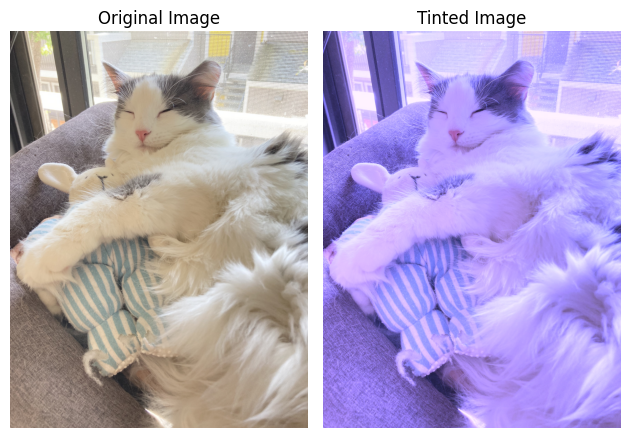

In [3]:

import numpy as np
import imageio
import matplotlib.pyplot as plt
from skimage.transform import resize

# Read an image from the 'assets' folder using imageio
img = imageio.imread('cat.jpg')
# Tint the image by scaling each color channel
img_tinted = img * [1, 0.95, 2]

# A slight gotcha with imshow is that it might give strange results
# if presented with data that is not uint8. To work around this, we
# explicitly cast the image to uint8 before displaying it.
img_tinted = np.clip(img_tinted, 0, 255).astype(np.uint8)

# Show the original image
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')  # Remove axes

# Show the tinted image
plt.subplot(1, 2, 2)
plt.imshow(img_tinted)
plt.title('Tinted Image')
plt.axis('off')  # Remove axes

# Display both images
plt.tight_layout()
plt.show()


## 2. Image Manipulations

You will be working with and manipulating either `messi.jpeg` or `cat.jpg` which is found in your repos.

**Tasks:**

1. **Image Display:**
   Load image`'messi.jpeg'` or `'cat.jpeg'` using PIL. Display the loaded image using matplotlib. You may find `open()` from PIL and `imshow()` from matplotlib useful.

2. **Image to Numpy Array:**
   Convert the image into a NumPy array and print its shape.

3. **Color Channels:**
   Split the image into its R, G, B channels and display each channel separately.

4. **Grayscale Conversion:**
   Convert the image to grayscale and display the grayscale image.

5. **Image Normalization:**
   Normalize the grayscale image such that values are in the range [0,1]. Print the minimum and maximum values before and after normalization.

6. **Image Crop:**
   Extract a center crop of 500x500 from the grayscale image and display the resized image.

7. **Convolution with Sobel Kernel:**
Manually apply convolution (do not use built-in functions like `numpy.convolve` or `scipy.signal.convolve2d`) to the cropped 500x500 image using the Sobel kernel provided below. Display the convoluted image.
   
   Sobel kernel:
   `[[-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]]`


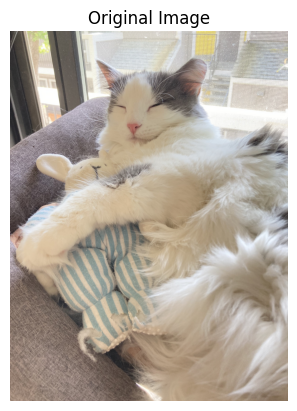

Image shape: (4032, 3024, 3)


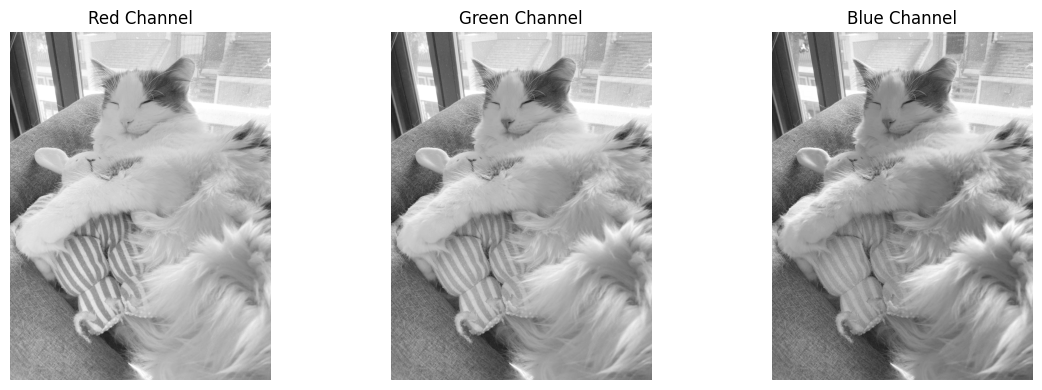

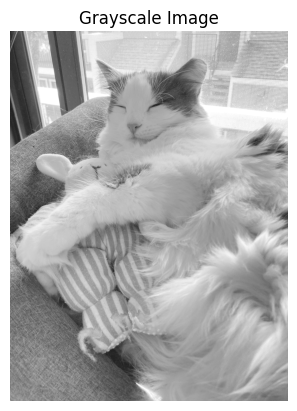

Before normalization:
Min: 0.7118 Max: 254.97449999999998
After normalization:
Min: 0.0 Max: 1.0
Crop shape: (500, 500)


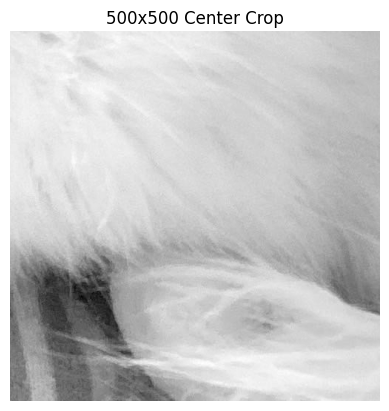

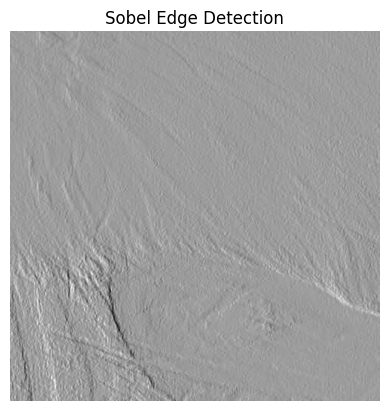

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# 1. Load the image using PIL & Display
img = Image.open('cat.jpg').convert('RGB')  # Ensure it's in RGB format
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')  # Remove axes for better visualization
plt.show()
# 2. Image to Numpy Array
img_array = np.array(img)
print("Image shape:", img_array.shape)  # Should print (height, width, channels)
# 3. Color Channels
R = img_array[:, :, 0]  # Red channel
G = img_array[:, :, 1]  # Green channel
B = img_array[:, :, 2]  # Blue channel
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(R, cmap='gray', vmin=0, vmax=255)
plt.title('Red Channel')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(G, cmap='gray', vmin=0, vmax=255)
plt.title('Green Channel')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(B, cmap='gray', vmin=0, vmax=255)
plt.title('Blue Channel')
plt.axis('off')

plt.tight_layout()
plt.show()

# 4. Grayscale Conversion
gray = 0.2989 * R + 0.5870 * G + 0.1140 * B
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()

# 5. Image Normalization
print("Before normalization:")
print("Min:", gray.min(), "Max:", gray.max())

gray_min = gray.min()
gray_max = gray.max()

if gray_max > gray_min:
    gray_norm = (gray - gray_min)/(gray_max- gray_min)
else:
    gray_norm=np.zeros_like(gray)

print("After normalization:")
print("Min:", gray_norm.min(), "Max:", gray_norm.max())

# 6. Image Center Crop
height, width = gray.shape

if height < 500 or width < 500:
    raise ValueError("Image must be at least 500x500 pixels for center cropping.")

start_y= (height - 500) // 2
start_x = (width - 500) // 2
crop = gray [start_y:start_y + 500, start_x:start_x + 500]

print("Crop shape:", crop.shape)

plt.imshow(crop, cmap='gray')
plt.title('500x500 Center Crop')
plt.axis('off')
plt.show()

# 7. Convolution with Sobel Kernel
sobel = np.array([[1, 0, -1],
                  [2, 0, -2],
                  [1, 0, -1]])

convolved = np.zeros((498, 498)) # Resulting size after convolution

for i in range(498):
    for j in range(498):
        region = crop[i:i+3, j:j+3]
        convolved[i, j] = np.sum(region * sobel)

plt.imshow(convolved, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')
plt.show()